# 00 · Аудит данных и границы выводов

**Кейс:** VK Case Champ 2026 — «Развитие элементов социальной коммерции для бизнес-сообществ во ВКонтакте».
**Роль:** аналитик команды. **Период данных:** 2026-09-01 — 2026-09-30 (30 дней).

## Зачем этот ноутбук
В кейсе прямо сказано: *«Часть данных окажется бесполезной, часть — запутает»* и
*«сначала проверь, насколько группы сопоставимы»*. Поэтому до любых выводов мы:

1. фиксируем, что за данные у нас есть и на каком уровне агрегации;
2. проверяем внутреннюю согласованность (внутри листа и между листами);
3. отделяем **факты** от **артефактов синтетики**;
4. формулируем, что по этим данным утверждать **нельзя** — это защита от неверных выводов на защите.

## Что вы получите на выходе
* таблицу-паспорт данных (`outputs/tables/00_data_dictionary.csv`);
* реестр аномалий (`outputs/tables/00_anomalies.csv`);
* сверку листов (`outputs/tables/00_reconciliation.csv`);
* список вопросов экспертам VK на Q&A-сессию.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vkcase import data, analysis as an, viz
from vkcase.config import VK, PARTNER, GOOD, BAD, GREY, SHEETS

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
%matplotlib inline

raw = data.load_raw()
d = data.load_all()
b = d["biz"]
print(f"Файл: {data.DATA_PATH}")
print(f"Листов: {len(raw)} | строк в «Бизнесы»: {len(b):,}")

Файл: C:\Users\Степан\Desktop\workspace\uploads\data.xlsx
Листов: 7 | строк в «Бизнесы»: 9,754


## 1. Паспорт данных: 7 листов, 3 разных уровня агрегации

Ключевая ловушка кейса: **лист «Бизнесы» и листы «Маркет…» описывают разные вселенные.**
Первый — выборка сообществ (микробизнес), вторые — платформенные итоги по товарной
вертикали, включая внешнего Партнёра (маркетплейс). Складывать их нельзя.

In [2]:
passport = pd.DataFrame([
    ["Бизнесы", "сообщество × 30 дней", len(raw["biz"]), 28,
     "сегментация, инструменты, контент, заказы через чекаут, реклама",
     "нет данных о продажах мимо чекаута (сообщения/внешний сайт)"],
    ["Маркет Вконтакте — итоги", "сегмент × 30 дней", len(raw["totals"]), 4,
     "воронка, GMV, покупатели, повторность, DAU/MAU",
     "Партнёр: нет «оплаченных заказов» (внешняя площадка)"],
    ["Маркет Вконтакте — по дням", "день × сегмент", len(raw["daily"]), 19,
     "динамика, тренды, сезонность недели, поиск",
     "уникальные пользователи по дням нельзя суммировать за месяц"],
    ["Маркет Вконтакте — источники", "источник × сегмент", len(raw["sources"]), 5,
     "структура трафика открытий карточки",
     "нет заказов в разрезе источника → конверсию по источнику не посчитать"],
    ["Маркет Вконтакте — категории", "категория × сегмент", len(raw["categories"]), 5,
     "конверсия по категориям, ассортиментный разрыв",
     "сумма заказов не сходится с итогами (см. сверку)"],
    ["Покупатели", "пол × возраст × сегмент", len(raw["buyers"]), 6,
     "профиль покупателя, заказов на покупателя",
     "группы <100 скрыты (NaN) → доли считаем от раскрытой базы"],
    ["Покупатели по регионам", "регион × сегмент", len(raw["regions"]), 5,
     "гео-концентрация, переиндексация регионов",
     "то же усечение групп <100; нет населения регионов"],
], columns=["лист", "гранулярность", "строк", "колонок", "что можно посчитать", "ограничение"])
data.save_table(passport, "00_data_dictionary")
passport

,лист,гранулярность,строк,колонок,что можно посчитать,ограничение
0,Бизнесы,сообщество × 30 дней,9754,28,"сегментация, инструменты, контент, заказы чере...",нет данных о продажах мимо чекаута (сообщения/...
1,Маркет Вконтакте — итоги,сегмент × 30 дней,26,4,"воронка, GMV, покупатели, повторность, DAU/MAU",Партнёр: нет «оплаченных заказов» (внешняя пло...
2,Маркет Вконтакте — по дням,день × сегмент,30,19,"динамика, тренды, сезонность недели, поиск",уникальные пользователи по дням нельзя суммиро...
3,Маркет Вконтакте — источники,источник × сегмент,7,5,структура трафика открытий карточки,нет заказов в разрезе источника → конверсию по...
4,Маркет Вконтакте — категории,категория × сегмент,18,5,"конверсия по категориям, ассортиментный разрыв",сумма заказов не сходится с итогами (см. сверку)
5,Покупатели,пол × возраст × сегмент,15,6,"профиль покупателя, заказов на покупателя",группы <100 скрыты (NaN) → доли считаем от рас...
6,Покупатели по регионам,регион × сегмент,89,5,"гео-концентрация, переиндексация регионов",то же усечение групп <100; нет населения регионов


In [3]:
print("Тип бизнеса:\n", b.btype.value_counts().to_string())
print("\nРазмерные группы по подписчикам:\n", b.size_band.value_counts().sort_index().to_string())
print(f"\nМедиана подписчиков: {b.subs.median():,.0f} | 90-й перцентиль: {b.subs.quantile(0.9):,.0f} | максимум: {b.subs.max():,.0f}")
print(f"Тематик: {b.theme.nunique()} | топ-5:\n{b.theme.value_counts().head(5).to_string()}")

Тип бизнеса:
 btype
без каталога           3168
товарное               3150
услужное               2428
товарное и услужное    1008

Размерные группы по подписчикам:
 size_band
0–100      2057
100–1k     4375
1k–10k     2904
10k–50k     361
50k+         57

Медиана подписчиков: 490 | 90-й перцентиль: 4,900 | максимум: 300,000
Тематик: 42 | топ-5:
theme
Красота и здоровье       1703
Кулинария и еда           837
Дом и ремонт              744
Творчество и хендмейд     538
Образование               537


**Наблюдение 1.** Выборка — это **микробизнес**: медиана 490 подписчиков, 75% сообществ
меньше 1 700 подписчиков. Крупных брендов в выборке практически нет.
Значит: выводы о поведении сообществ справедливы для длинного хвоста СМБ,
а платформенные GMV/заказы формируются в основном **за пределами этой выборки**.

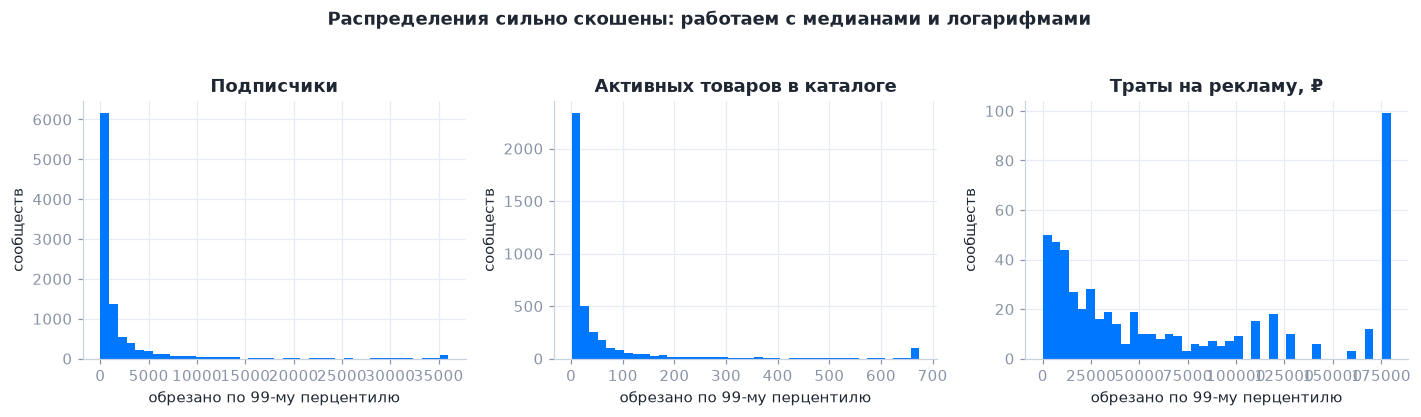

WindowsPath('C:/Users/Степан/Desktop/workspace/outputs/figures/00_distributions.png')

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, title in zip(
    axes,
    ["subs", "sku_active", "ad_spend"],
    ["Подписчики", "Активных товаров в каталоге", "Траты на рекламу, ₽"],
):
    v = b[col].clip(upper=b[col].quantile(0.99))
    ax.hist(v[v > 0], bins=40, color=VK)
    ax.set_title(title)
    ax.set_xlabel("обрезано по 99-му перцентилю")
    ax.set_ylabel("сообществ")
fig.suptitle("Распределения сильно скошены: работаем с медианами и логарифмами", fontweight="bold", y=1.04)
fig.tight_layout(); viz.save(fig, "00_distributions")

## 2. Пропуски и нули: что informatивно, а что — нет

* `Средний чек` заполнен только у 291 сообщества — ровно там, где есть GMV. Это **не пропуск, а отсутствие события**.
* `Медианная цена товара` — у 4 342 (есть каталог).
* `Автор оригинального контента (оценка модели)` — 2 570 пропусков (26,3%), причём **равномерно по типам бизнеса**
  → можно импутировать с индикатором, но это модельная оценка, а не факт.

In [5]:
miss = pd.DataFrame({
    "пропусков": b.isna().sum(),
    "доля_пропусков": b.isna().mean(),
    "нулей": (b == 0).sum(numeric_only=True),
}).sort_values("доля_пропусков", ascending=False)
miss = miss[miss["пропусков"] > 0]
data.save_table(miss.reset_index(names="поле"), "00_missing")
miss

,пропусков,доля_пропусков,нулей
aov_col,9463,0.9702,0
aov_calc,9456,0.9694,7
vpp_prod,9451,0.9689,0
orders_per_1k_opens,9317,0.9552,358
roas,9212,0.9444,503
er_prod,8438,0.8651,795
card_ctr,8438,0.8651,919
price_median,5412,0.5548,3
orig_author,2570,0.2635,5390
vpp_reg,2373,0.2433,48


In [6]:
print("Пропуски «Автор оригинального контента» по типам бизнеса (проверка на MAR):")
print(b.groupby("btype").orig_author.apply(lambda s: s.isna().mean()).round(3).to_string())

Пропуски «Автор оригинального контента» по типам бизнеса (проверка на MAR):
btype
без каталога          0.2890
товарное              0.2710
товарное и услужное   0.1880
услужное              0.2510


## 3. Реестр аномалий: 6 логических противоречий

Мы **не удаляем** такие строки (это исказило бы структуру выборки), а помечаем флагами
и проверяем, влияют ли они на выводы.

In [7]:
anomalies = pd.DataFrame([
    ["Чекаут подключён, но каталог пуст", int(b.flag_checkout_no_catalog.sum()),
     "Технически чекаут без товаров невозможен. Либо признак «чекаут» = доступность функции, либо товары услуг.",
     "Не считаем такие сообщества «готовыми к продажам»; выделяем в отдельный сегмент S2."],
    ["Просмотры товарного контента есть, публикаций с товаром нет", int(b.flag_views_no_posts.sum()),
     "Просмотры могли прийти из витрины/карточек, а не из постов; либо разная атрибуция окон.",
     "Парные тесты контента проводим только на сообществах, где есть и публикации, и просмотры."],
    ["Открытия карточки > просмотров товарного контента", int(b.flag_opens_gt_views.sum()),
     "Нарушение вложенности воронки.", "Исключаем из расчёта CTR карточки."],
    ["Заказы > 0, но GMV = 0", int(b.flag_orders_no_gmv.sum()),
     "Нулевые/незаполненные суммы.", "AOV считаем как GMV/заказы на агрегате, не по строкам."],
    ["Доставка или оплата без чекаута", int(b.flag_tools_no_checkout.sum()),
     "Нарушение логики стека.", "В воронке стека используем строгую вложенность."],
    ["Колонка «Средний чек» ≠ GMV/заказы", int(b.aov_col.notna().sum()),
     "Медианное отношение расчётного чека к колонке ≈ 1,18 при корреляции 0,995.",
     "Везде используем расчётный AOV = GMV / заказы."],
], columns=["аномалия", "строк", "почему это проблема", "как обрабатываем"])
data.save_table(anomalies, "00_anomalies")
anomalies

,аномалия,строк,почему это проблема,как обрабатываем
0,"Чекаут подключён, но каталог пуст",2096,Технически чекаут без товаров невозможен. Либо...,Не считаем такие сообщества «готовыми к продаж...
1,"Просмотры товарного контента есть, публикаций ...",1013,"Просмотры могли прийти из витрины/карточек, а ...",Парные тесты контента проводим только на сообщ...
2,Открытия карточки > просмотров товарного контента,40,Нарушение вложенности воронки.,Исключаем из расчёта CTR карточки.
3,"Заказы > 0, но GMV = 0",7,Нулевые/незаполненные суммы.,"AOV считаем как GMV/заказы на агрегате, не по ..."
4,Доставка или оплата без чекаута,168,Нарушение логики стека.,В воронке стека используем строгую вложенность.
5,Колонка «Средний чек» ≠ GMV/заказы,291,Медианное отношение расчётного чека к колонке ...,Везде используем расчётный AOV = GMV / заказы.


In [8]:
m = b.aov_col.notna()
print(f"Корреляция «Средний чек» и GMV/заказы: {b.loc[m,'aov_calc'].corr(b.loc[m,'aov_col']):.4f}")
print(f"Медианное отношение (расчёт / колонка): {(b.loc[m,'aov_calc']/b.loc[m,'aov_col']).median():.3f}")
b.loc[m, ["biz_id", "orders", "gmv", "aov_calc", "aov_col"]].head(8)

Корреляция «Средний чек» и GMV/заказы: 0.9953
Медианное отношение (расчёт / колонка): 1.180


,biz_id,orders,gmv,aov_calc,aov_col
2,5330,83,17150,206.6265,208.0000
3,5072,2,6250,"3,125.0000","2,648.0000"
8,4977,7,5350,764.2857,756.0000
12,4480,7,104000,"14,857.1429","14,690.0000"
15,8757,54,431530,"7,991.2963","7,950.0000"
18,2543,4,27380,"6,845.0000","7,733.0000"
23,9368,5,46750,"9,350.0000","9,905.0000"
24,8344,44,75400,"1,713.6364","1,727.0000"


## 4. Сверка листов: что сходится, а что нет

Это обязательный шаг: если суммы не сходятся, любые «доли» и «конверсии» могут быть неверными.

In [9]:
t = d["totals"]
num = lambda metric, col="Маркет Вконтакте": float(pd.to_numeric(pd.Series([t.loc[metric, col]]), errors="coerce").iloc[0])
pairs = [
    ("Показы товаров", "Показы товаров: Маркет Вконтакте", "Показы товаров: Партнёр 1", "поток"),
    ("Открытия карточки товара", "Открытия карточки: Маркет Вконтакте", "Открытия карточки: Партнёр 1", "поток"),
    ("Нажатия на кнопку в карточке", "Нажатия на кнопку: Маркет Вконтакте", "Нажатия на кнопку: Партнёр 1", "поток"),
    ("Оформленные заказы", "Заказы: Маркет Вконтакте", "Заказы: Партнёр 1", "поток"),
    ("GMV, ₽", "GMV, ₽: Маркет Вконтакте", "GMV, ₽: Партнёр 1", "поток"),
    ("Уникальные покупатели за 30 дней", "Покупатели: Маркет Вконтакте", "Покупатели: Партнёр 1", "уникальные"),
]
rows = []
for metric, cvk, cpt, kind in pairs:
    for who, col, tcol in [("Маркет ВКонтакте", cvk, "Маркет Вконтакте"), ("Партнёр 1", cpt, "Партнёр 1")]:
        tot, days = num(metric, tcol), d["daily"][col].sum()
        rows.append({"метрика": metric, "сегмент": who, "тип": kind,
                     "итоги": tot, "сумма по дням": days, "расхождение": days / tot - 1})
rec = pd.DataFrame(rows)
data.save_table(rec, "00_reconciliation")
rec

,метрика,сегмент,тип,итоги,сумма по дням,расхождение
0,Показы товаров,Маркет ВКонтакте,поток,"4,777,750,023.0000",4777750023,0.0000
1,Показы товаров,Партнёр 1,поток,"5,729,628,790.0000",5729628790,0.0000
2,Открытия карточки товара,Маркет ВКонтакте,поток,"193,512,461.0000",193512461,0.0000
3,Открытия карточки товара,Партнёр 1,поток,"86,882,822.0000",86882822,0.0000
4,Нажатия на кнопку в карточке,Маркет ВКонтакте,поток,"5,969,063.0000",5969063,0.0000
5,Нажатия на кнопку в карточке,Партнёр 1,поток,"36,626,075.0000",36626075,0.0000
6,Оформленные заказы,Маркет ВКонтакте,поток,"413,740.0000",413740,0.0000
7,Оформленные заказы,Партнёр 1,поток,"4,927,525.0000",4927525,0.0000
8,"GMV, ₽",Маркет ВКонтакте,поток,"1,564,546,740.0000",1564546740,0.0000
9,"GMV, ₽",Партнёр 1,поток,"5,119,514,685.0000",5119514684,-0.0000


**Читается так:**
* Все **потоковые** метрики (показы, открытия, нажатия, заказы, GMV) сходятся **день в день, до рубля** → дневным данным доверяем.
* **Уникальные покупатели** по дням в сумме больше месячных (+21,5% у Маркета, +36,2% у Партнёра) — это **не ошибка**:
  один человек покупает в разные дни. Отсюда же вывод: месячная база покупателей Маркета 296 тыс., а не 360 тыс.

Ниже — сверки, которые **не сходятся** и требуют оговорки в презентации.

In [10]:
src, cat, byr, reg = d["sources"], d["categories"], d["buyers"], d["regions"]
checks = pd.DataFrame([
    ["Источники: сумма открытий = итоги (Маркет)", src["Маркет Вконтакте"].sum(), num("Открытия карточки товара"), "OK"],
    ["Источники: сумма открытий = итоги (Партнёр)", src["Партнёр 1"].sum(), num("Открытия карточки товара", "Партнёр 1"), "OK"],
    ["Категории: сумма открытий (Маркет)", cat.opens_vk.sum(), num("Открытия карточки товара"), "≈0,02% — округление"],
    ["Категории: сумма заказов (Маркет)", cat.orders_vk.sum(), num("Оформленные заказы"), "РАСХОЖДЕНИЕ +5,2%"],
    ["Категории: сумма заказов (Партнёр)", cat.orders_pt.sum(), num("Оформленные заказы", "Партнёр 1"), "РАСХОЖДЕНИЕ −7,5%"],
    ["Покупатели (пол×возраст): база Маркета", byr.buyers_vk.sum(), num("Уникальные покупатели за 30 дней"), "усечение групп <100"],
    ["Покупатели (пол×возраст): база Партнёра", byr.buyers_pt.sum(), num("Уникальные покупатели за 30 дней", "Партнёр 1"), "усечение групп <100"],
    ["Открытия «из постов и клипов» (итоги)", 86_321_893,
     src.loc[src["Источник"].isin(["Лента", "Клипы"]), ["Маркет Вконтакте", "Партнёр 1"]].sum().sum(),
     "РАСХОЖДЕНИЕ −26%: разная атрибуция"],
    ["Реферальные открытия (итоги) vs открытия Партнёра из контента", 82_324_081,
     src.loc[src["Источник"].isin(["Лента", "Клипы"]), "Партнёр 1"].sum(),
     "реферальные > контентных: рефералка учитывается шире источников"],
], columns=["проверка", "значение_1", "значение_2", "вердикт"])
checks["расхождение"] = checks.значение_1 / checks.значение_2 - 1
data.save_table(checks, "00_cross_sheet_checks")
checks

,проверка,значение_1,значение_2,вердикт,расхождение
0,Источники: сумма открытий = итоги (Маркет),"193,512,461.0000","193,512,461.0000",OK,0.0000
1,Источники: сумма открытий = итоги (Партнёр),"86,882,822.0000","86,882,822.0000",OK,0.0000
2,Категории: сумма открытий (Маркет),"193,472,512.0000","193,512,461.0000","≈0,02% — округление",-0.0002
3,Категории: сумма заказов (Маркет),"435,285.0000","413,740.0000","РАСХОЖДЕНИЕ +5,2%",0.0521
4,Категории: сумма заказов (Партнёр),"4,557,517.0000","4,927,525.0000","РАСХОЖДЕНИЕ −7,5%",-0.0751
5,Покупатели (пол×возраст): база Маркета,"295,850.0000","296,148.0000",усечение групп <100,-0.0010
6,Покупатели (пол×возраст): база Партнёра,"2,901,162.0000","2,901,334.0000",усечение групп <100,-0.0001
7,Открытия «из постов и клипов» (итоги),"86,321,893.0000","116,574,257.0000",РАСХОЖДЕНИЕ −26%: разная атрибуция,-0.2595
8,Реферальные открытия (итоги) vs открытия Партн...,"82,324,081.0000","80,539,495.0000",реферальные > контентных: рефералка учитываетс...,0.0222


### 4.1. Две аномалии, которые нельзя показывать на слайде как факт

1. **Категория «Не определена» у Партнёра: 0 открытий карточки, но 117 818 заказов.**
   Заказ без открытия технически возможен (прямые переходы), но тогда это не «категория»,
   а нераспознанная атрибуция. Из расчёта конверсии по категориям исключаем.
2. **Категория «Другое» у Маркета: 29,1 млн открытий → 41 заказ.** Это не «плохая конверсия»,
   это, скорее всего, служебная/нетоварная корзина трафика. Но именно она — 15% всего трафика Маркета.

In [11]:
cat[["category", "opens_vk", "orders_vk", "conv_vk", "opens_pt", "orders_pt", "conv_pt"]].sort_values("opens_vk", ascending=False)

,category,opens_vk,orders_vk,conv_vk,opens_pt,orders_pt,conv_pt
0,Гардероб,33022954,29029,0.0009,9023244,259808,0.0288
1,Хобби и развлечения,32048705,110703,0.0035,2474633,116999,0.0473
2,Другое,29082926,41,0.0000,160,0,0.0000
3,Дом и дача,26162824,35976,0.0014,24528887,1413965,0.0576
4,Продукты питания,20393319,195355,0.0096,2488477,170556,0.0685
5,Красота и здоровье,11345073,13022,0.0011,14113274,1240324,0.0879
6,Транспорт,8590002,8254,0.0010,4569160,264510,0.0579
7,Электроника,5768728,4519,0.0008,2786808,30616,0.0110
8,Спорт и отдых,5632947,7781,0.0014,4092740,179554,0.0439
9,Детские товары,4859516,10546,0.0022,2478504,102803,0.0415


## 5. Главная «дыра» измерения: заказ ≠ оплата ≠ деньги

Это критично для вопроса кейса *«а если продажа заканчивается на внешнем сайте, мы её увидим?»*.

In [12]:
orders_vk = num("Оформленные заказы")
paid_vk = num("Оплаченные заказы")
print(f"Маркет ВКонтакте: оформлено {orders_vk:,.0f} заказов, оплачено внутри VK {paid_vk:,.0f} → {paid_vk/orders_vk:.2%}")
print(f"Партнёр 1: оформлено {num('Оформленные заказы','Партнёр 1'):,.0f}, оплаченных данных нет (внешняя площадка)")
print(f"\nВ выборке сообществ оплата подключена у {b.payment.mean():.2%}, доставка у {b.delivery.mean():.2%}")
print(f"Прямых переходов к Партнёру без открытия карточки: {num('Прямые переходы к Партнёру 1 (без открытия карточки)','Партнёр 1'):,.0f}")

Маркет ВКонтакте: оформлено 413,740 заказов, оплачено внутри VK 4,903 → 1.19%
Партнёр 1: оформлено 4,927,525, оплаченных данных нет (внешняя площадка)

В выборке сообществ оплата подключена у 2.61%, доставка у 9.42%
Прямых переходов к Партнёру без открытия карточки: 106,914,679


**Вывод (важнейший для стратегии монетизации).**
ВКонтакте наблюдает **1,2% заказов как оплаченные**. Остальные 98,8% — «оформленные»:
договорённость в сообщениях, переход на внешний сайт, оплата при получении.
Следовательно:

* мы **не можем** посчитать реальную выручку бизнеса и ROI рекламы по этим данным;
* комиссия с GMV как модель монетизации сегодня **технически не обеспечена** — сначала нужен чекаут+оплата;
* любой ROAS, посчитанный по `GMV через чекаут / Траты на рекламу`, — это **нижняя оценка**, а не эффективность рекламы.

## 6. Насколько выборка сообществ репрезентативна для платформы

Проверяем «сшивку» двух вселенных.

In [13]:
comp = pd.DataFrame([
    ["Заказы", b.orders.sum(), orders_vk, "выборка / платформенные оформленные"],
    ["Заказы", b.orders.sum(), paid_vk, "выборка / платформенные оплаченные"],
    ["GMV, ₽", b.gmv.sum(), num("GMV, ₽"), "выборка / платформенный GMV"],
    ["Открытия карточки из контента", b.card_opens.sum(), 86_321_893, "выборка / платформенные из постов и клипов"],
], columns=["метрика", "выборка_9754", "платформа", "сравнение"])
comp["доля_выборки"] = comp.выборка_9754 / comp.платформа
data.save_table(comp, "00_sample_vs_platform")
comp

,метрика,выборка_9754,платформа,сравнение,доля_выборки
0,Заказы,3478,"413,740.0000",выборка / платформенные оформленные,0.0084
1,Заказы,3478,"4,903.0000",выборка / платформенные оплаченные,0.7094
2,"GMV, ₽",9973027,"1,564,546,740.0000",выборка / платформенный GMV,0.0064
3,Открытия карточки из контента,53068,"86,321,893.0000",выборка / платформенные из постов и клипов,0.0006


**Интерпретация.**
* Выборка даёт **0,64% платформенного GMV**, но **71% «оплаченных» заказов** →
  она покрывает почти весь *микро*-чекаут, но не крупные продажи.
* Значит: **нельзя** экстраполировать средние по выборке на «более миллиона сообществ».
  Правильная логика: на выборке оцениваем **механику и направления эффектов**,
  а объёмы считаем от платформенных итогов (лист «итоги» / «по дням»).

Именно так построен ноутбук 04 (сценарная модель).

## 7. Что можно и что нельзя утверждать по этим данным

| Можно | Нельзя |
|---|---|
| Структуру подключения инструментов и разрыв «подключил → продал» | Реальную выручку и ROI бизнеса (нет продаж мимо чекаута) |
| Где именно теряется воронка Маркета (пошагово) | Конверсию по источникам трафика (нет заказов × источник) |
| Ассоциации признаков с фактом продажи (логит, PSM) | Причинный эффект инструментов (наблюдательные данные, self-selection) |
| Структуру ассортимента и «мёртвый трафик» по категориям | Точные доли категорий (сумма заказов расходится на 5–7%) |
| Тренды за 30 дней и эффект дня недели | Годовую сезонность и долгосрочный рост (один месяц) |
| Профиль покупателей и гео-концентрацию | Проникновение на население региона (нет населения) |

In [14]:
questions = pd.DataFrame([
    ["Что именно означает флаг «Подключён чекаут», если каталог пуст (2 096 сообществ)?", "определяет размер целевого сегмента"],
    ["«Оформленные заказы» Маркета — это заказ в чекауте или заявка в сообщения?", "от этого зависит вся модель монетизации"],
    ["Почему «оплаченные заказы» = 1,2% от оформленных: только оплата внутри VK или сбой учёта?", "оценка потенциала комиссии"],
    ["Как атрибутируются «открытия из постов и клипов» (86,3 млн) vs источники «Лента+Клипы» (116,6 млн)?", "оценка вклада контента"],
    ["Есть ли данные по заказам в разрезе источника трафика и по возвратам/выкупу?", "без них не посчитать юнит-экономику"],
    ["Как формировалась выборка 9 754 сообществ из >1 млн: случайно или по фильтру?", "границы переноса выводов"],
    ["Что за «Партнёр 1»: один маркетплейс или агрегация? Учитываются ли его заказы как заказы VK?", "цели по заказам внутри VK"],
], columns=["вопрос экспертам VK (Q&A 16 ноября)", "зачем нужен ответ"])
data.save_table(questions, "00_questions_to_experts")
questions

,вопрос экспертам VK (Q&A 16 ноября),зачем нужен ответ
0,"Что именно означает флаг «Подключён чекаут», е...",определяет размер целевого сегмента
1,«Оформленные заказы» Маркета — это заказ в чек...,от этого зависит вся модель монетизации
2,"Почему «оплаченные заказы» = 1,2% от оформленн...",оценка потенциала комиссии
3,Как атрибутируются «открытия из постов и клипо...,оценка вклада контента
4,Есть ли данные по заказам в разрезе источника ...,без них не посчитать юнит-экономику
5,Как формировалась выборка 9 754 сообществ из >...,границы переноса выводов
6,Что за «Партнёр 1»: один маркетплейс или агрег...,цели по заказам внутри VK


In [15]:
data.save_key_numbers({
    "n_businesses": len(b),
    "subs_median": b.subs.median(),
    "share_paid_of_orders_vk": paid_vk / orders_vk,
    "checkout_connected": int((b.checkout == 1).sum()),
    "delivery_connected": int((b.delivery == 1).sum()),
    "payment_connected": int((b.payment == 1).sum()),
    "sellers": int((b.orders > 0).sum()),
    "sample_gmv": float(b.gmv.sum()),
    "sample_orders": int(b.orders.sum()),
    "sample_ad_spend": float(b.ad_spend.sum()),
    "sample_share_of_platform_gmv": float(b.gmv.sum() / num("GMV, ₽")),
    "checkout_without_catalog": int(b.flag_checkout_no_catalog.sum()),
}, "00_audit")
print("Сохранено: outputs/tables/00_*.csv, outputs/key_numbers.json")

Сохранено: outputs/tables/00_*.csv, outputs/key_numbers.json


## Итоги ноутбука 00

1. **Данным о воронке можно доверять**: дневные потоки сходятся с итогами до рубля.
2. **Выборка сообществ — микро-СМБ** (медиана 490 подписчиков) и покрывает 0,64% платформенного GMV.
   Механику изучаем на ней, объёмы считаем от платформенных метрик.
3. **6 логических аномалий** задокументированы и обработаны флагами, а не удалением.
4. **98,8% заказов не наблюдаются как оплаченные** → монетизация комиссией сегодня не обеспечена,
   а ROAS по чекауту — нижняя оценка.
5. Расхождения по категориям (5–7%) и по атрибуции контента (26%) → на слайдах используем
   структурные выводы, а не точные доли.

**Дальше:** ноутбук 01 — сегментация бизнесов и воронка активации.